# 04 — RFM Customer Segmentation

**Objective:** segment all qualifying customers by Recency, Frequency and
Monetary value to identify where retention effort could pay off.

**Method:**
* Reference date = day after last observed purchase (**2018-10-18**), not
  today's date — the data ends Oct-2018.
* R and M scored into quintiles; F uses fixed bins (1,2,3,4,5+) because
  ~97% of customers have frequency 1 (a quintile on F is meaningless).
* Segments assigned by ordered rules — see docs/methodology.md.

In [1]:
import sys
from pathlib import Path

# Make the repo's src/ package importable when running from notebooks/.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data_loading as dl
from src.config import get_engine
from src.visualization import PALETTE, set_style

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
engine = get_engine()


In [2]:
rfm = dl.load_table("analytics.rfm_customers", engine)
rfm[["recency_days","frequency","monetary_brl",
     "r_score","f_score","m_score","rfm_segment"]].describe(include="all")

,recency_days,frequency,monetary_brl,r_score,f_score,m_score,rfm_segment
count,"93,358.00","93,358.00","93,358.00","93,358.00","93,358.00","93,358.00",93358
unique,NaN,NaN,NaN,NaN,NaN,NaN,9
top,NaN,NaN,NaN,NaN,NaN,NaN,Recent One-Time Buyers
freq,NaN,NaN,NaN,NaN,NaN,NaN,36141
mean,238.48,1.03,165.17,3.00,1.03,3.00,NaN
std,152.60,0.21,226.29,1.41,0.20,1.41,NaN
min,1.00,1.00,9.59,1.00,1.00,1.00,NaN
25%,115.00,1.00,63.01,2.00,1.00,2.00,NaN
50%,219.00,1.00,107.78,3.00,1.00,3.00,NaN
75%,347.00,1.00,182.51,4.00,1.00,4.00,NaN


## R, F, M distributions

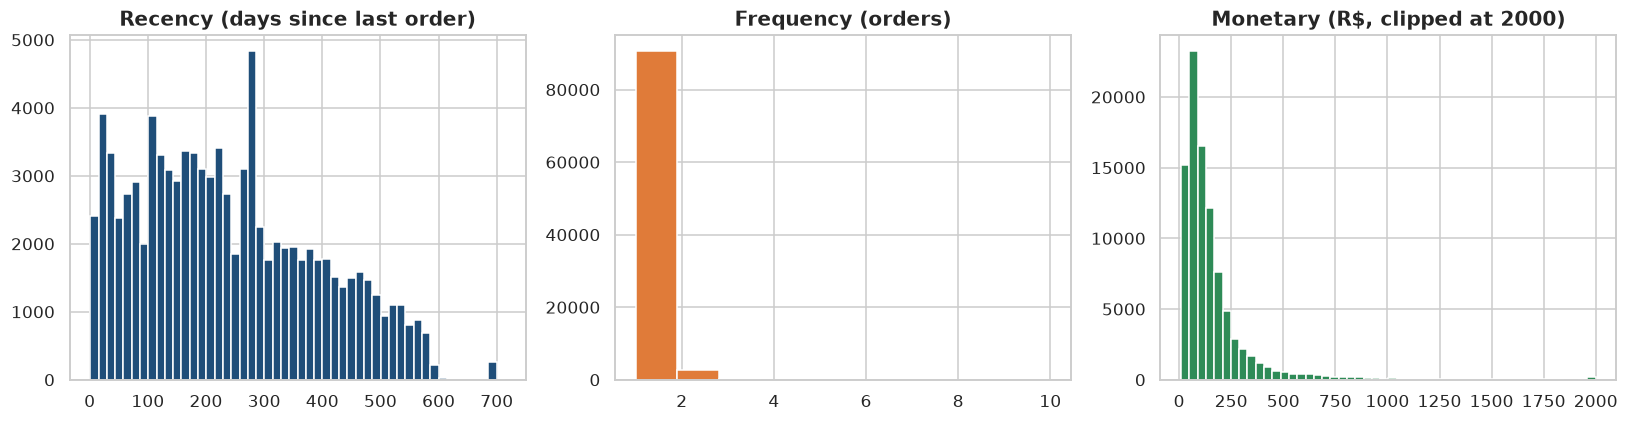

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(rfm["recency_days"], bins=50, color=PALETTE["primary"])
axes[0].set_title("Recency (days since last order)")
axes[1].hist(rfm["frequency"].clip(0, 10), bins=10, color=PALETTE["accent"])
axes[1].set_title("Frequency (orders)")
axes[2].hist(rfm["monetary_brl"].clip(0, 2000), bins=50,
             color=PALETTE["good"])
axes[2].set_title("Monetary (R$, clipped at 2000)")
fig.tight_layout(); plt.show()

## Segment summary

In [4]:
seg = dl.load_table("analytics.rfm_segments", engine)
seg

,rfm_segment,customers,pct_customers,total_revenue_brl,pct_revenue,avg_spend_brl,avg_recency_days,avg_frequency,avg_review_score,late_delivery_pct
0,Recent One-Time Buyers,36141,38.71,"5,937,383.95",38.51,164.28,91.00,1.00,4.21,6.40
1,High-Value Inactive,13782,14.76,"4,241,493.71",27.51,307.76,394.00,1.00,4.12,6.30
2,Other One-Time Buyers,18064,19.35,"2,735,830.98",17.74,151.45,220.00,1.00,4.00,10.10
3,Inactive One-Time Buyers,22570,24.18,"1,640,877.65",10.64,72.70,396.00,1.00,4.20,5.20
4,Potential Loyalists,1080,1.16,"320,750.41",2.08,296.99,89.00,2.00,4.27,5.60
5,At Risk,992,1.06,"292,592.95",1.90,294.95,382.00,2.08,4.21,4.10
6,Needs Attention,571,0.61,"165,029.59",1.07,289.02,218.00,2.00,4.03,9.10
7,Champions,116,0.12,"66,290.87",0.43,571.47,91.00,3.54,4.45,4.40
8,Loyal Customers,42,0.04,"19,523.64",0.13,464.85,196.00,3.43,4.21,6.90


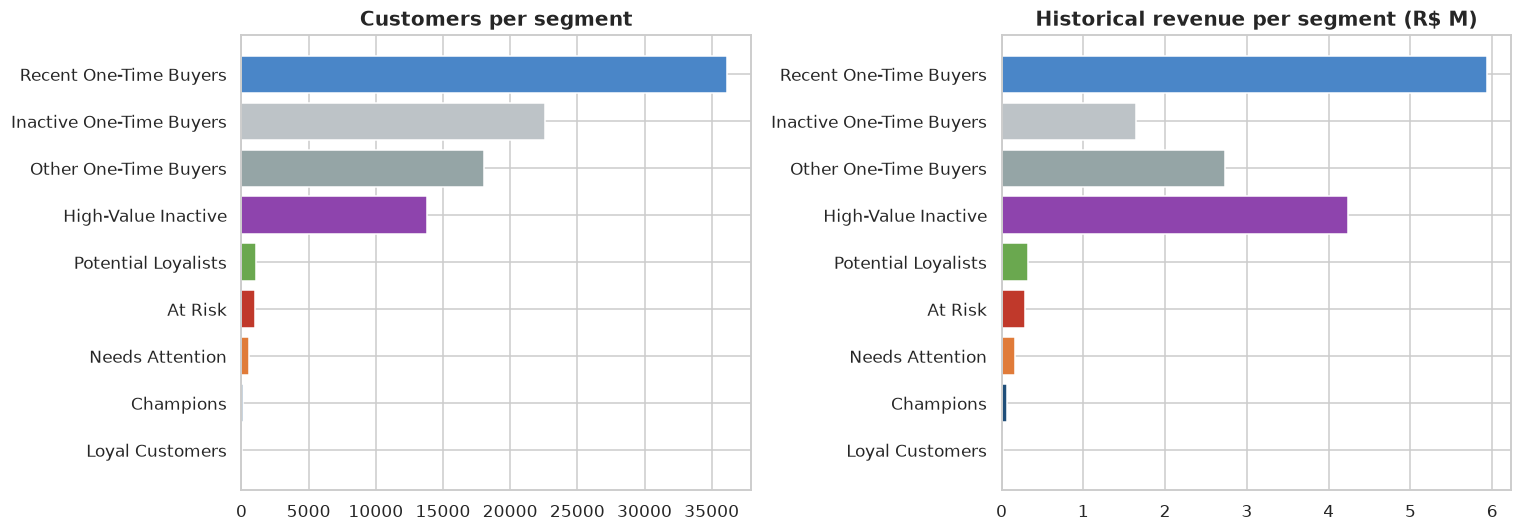

In [5]:
from src.visualization import SEGMENT_COLORS
s = seg.sort_values("customers", ascending=True)
colors = [SEGMENT_COLORS.get(x, "#8a8d91") for x in s["rfm_segment"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(s["rfm_segment"], s["customers"], color=colors)
axes[0].set_title("Customers per segment")
axes[1].barh(s["rfm_segment"], s["total_revenue_brl"]/1e6, color=colors)
axes[1].set_title("Historical revenue per segment (R$ M)")
fig.tight_layout(); plt.show()

**Reading:** the four one-time-buyer segments hold ~97% of customers.
'High-Value Inactive' is notable — 13.8k customers who each spent ~R$308
on average (about twice the overall AOV) but haven't returned in ~13
months. 'At Risk' and 'Needs Attention' are the small pools of proven
repeat buyers who have gone quiet.

## Recency vs monetary scatter (sample)

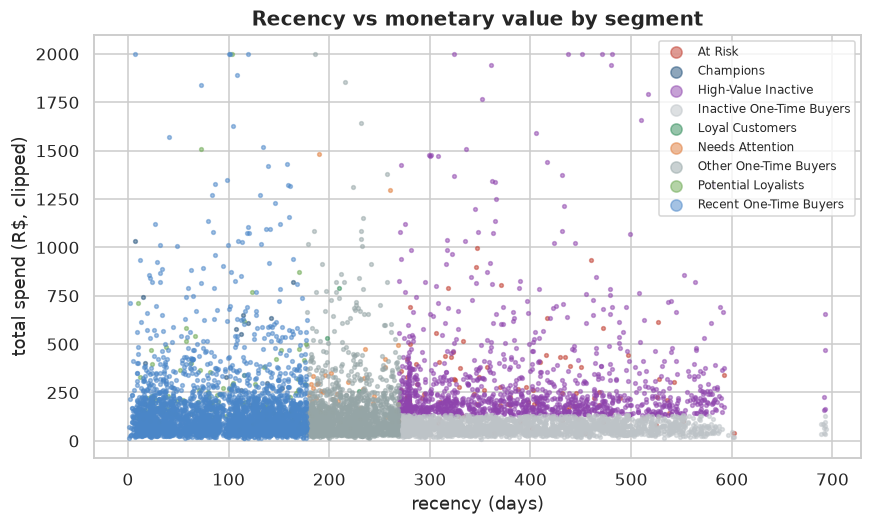

In [6]:
sample = rfm.sample(8000, random_state=42)
fig, ax = plt.subplots(figsize=(9, 5))
for name, grp in sample.groupby("rfm_segment"):
    ax.scatter(grp["recency_days"], grp["monetary_brl"].clip(0, 2000),
               s=6, alpha=0.5, label=name,
               color=SEGMENT_COLORS.get(name))
ax.set_title("Recency vs monetary value by segment")
ax.set_xlabel("recency (days)"); ax.set_ylabel("total spend (R$, clipped)")
ax.legend(markerscale=3, fontsize=8)
plt.show()

## Conclusion

* Segmentation is heavily skewed to one-time buyers — consistent with the
  3% repeat rate.
* **High-Value Inactive** = biggest historical revenue pool after Recent
  One-Time Buyers (R$4.2M, 27% of revenue) with proven willingness to
  spend — the most defensible re-engagement target.
* Repeat-capable segments (Champions, Loyal, Potential Loyalists,
  Needs Attention, At Risk) are tiny (~3,800 customers combined) but
  already show multi-order behaviour.
* Every segment assignment is validated in sql/09_validation_tests.sql
  (counts reconcile to the customer population, no null segments).